# 02 · Dataset y análisis exploratorio
Se generan 50 000 planetas (LHS) con `python -m worldsim.data.generate`. Aquí solo cargamos y exploramos, **antes de modelar**.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

In [2]:
from pathlib import Path
if not Path('data/worlds.npz').exists():
    from worldsim.data import generate
    import yaml
    d = generate.generate(yaml.safe_load(open('configs/dataset.yaml', encoding='utf8'))); Path('data').mkdir(exist_ok=True); np.savez_compressed('data/worlds.npz', **d)
from worldsim.data.dataset import load_worlds
w = load_worlds()
print(w.X.shape, w.traj.shape, 'split train/val/test:', [int((w.split==i).sum()) for i in range(3)])

(50000, 11) (50000, 101, 4) split train/val/test: [35000, 7500, 7500]


{'surv_train': 0.6347714066505432, 'surv_val': 0.6290666460990906, 'surv_test': 0.6265333294868469, 't_collapse_quantiles': [60.0, 123.0, 289.0, 365.0, 509.0], 'n': 50000, 'survival_rate': 0.6326799988746643, 'mc_p_true_mean': 0.6678125262260437, 'mc_share_intermediate': 0.178}


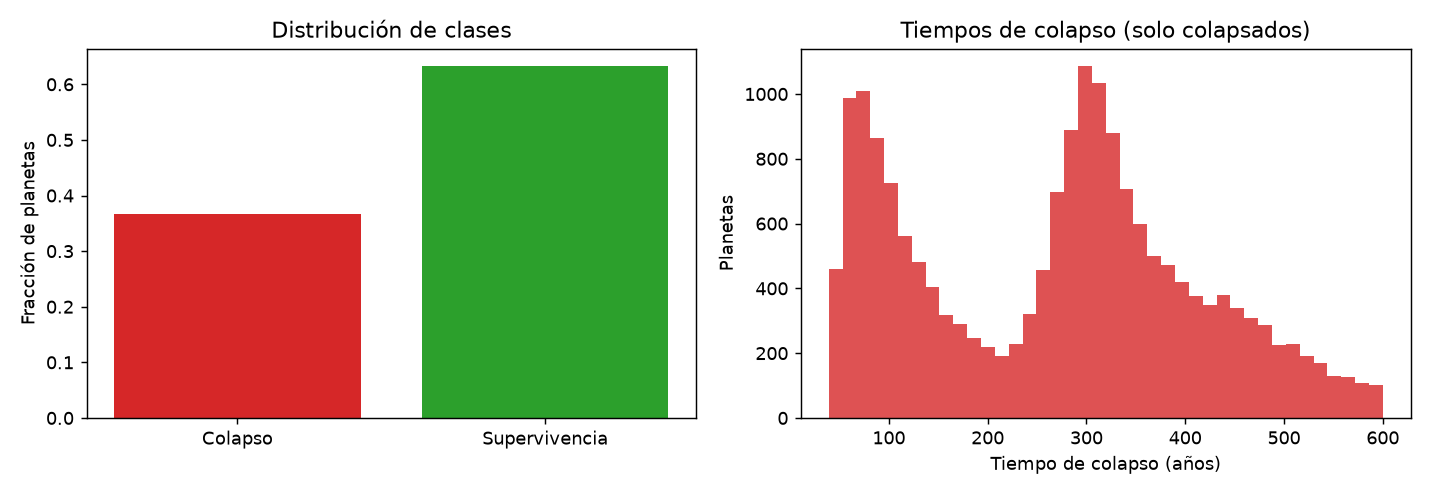

In [3]:
from worldsim.reporting import eda
stats = eda(w)
print(stats)
display(Image('report/figures/fig_eda_clases_tiempos.png'))

## Trayectorias: 3 que sobreviven y 3 que colapsan
Línea azul: población; verde discontinua: naturaleza; franjas naranjas: eventos extremos; línea roja: tiempo de colapso.

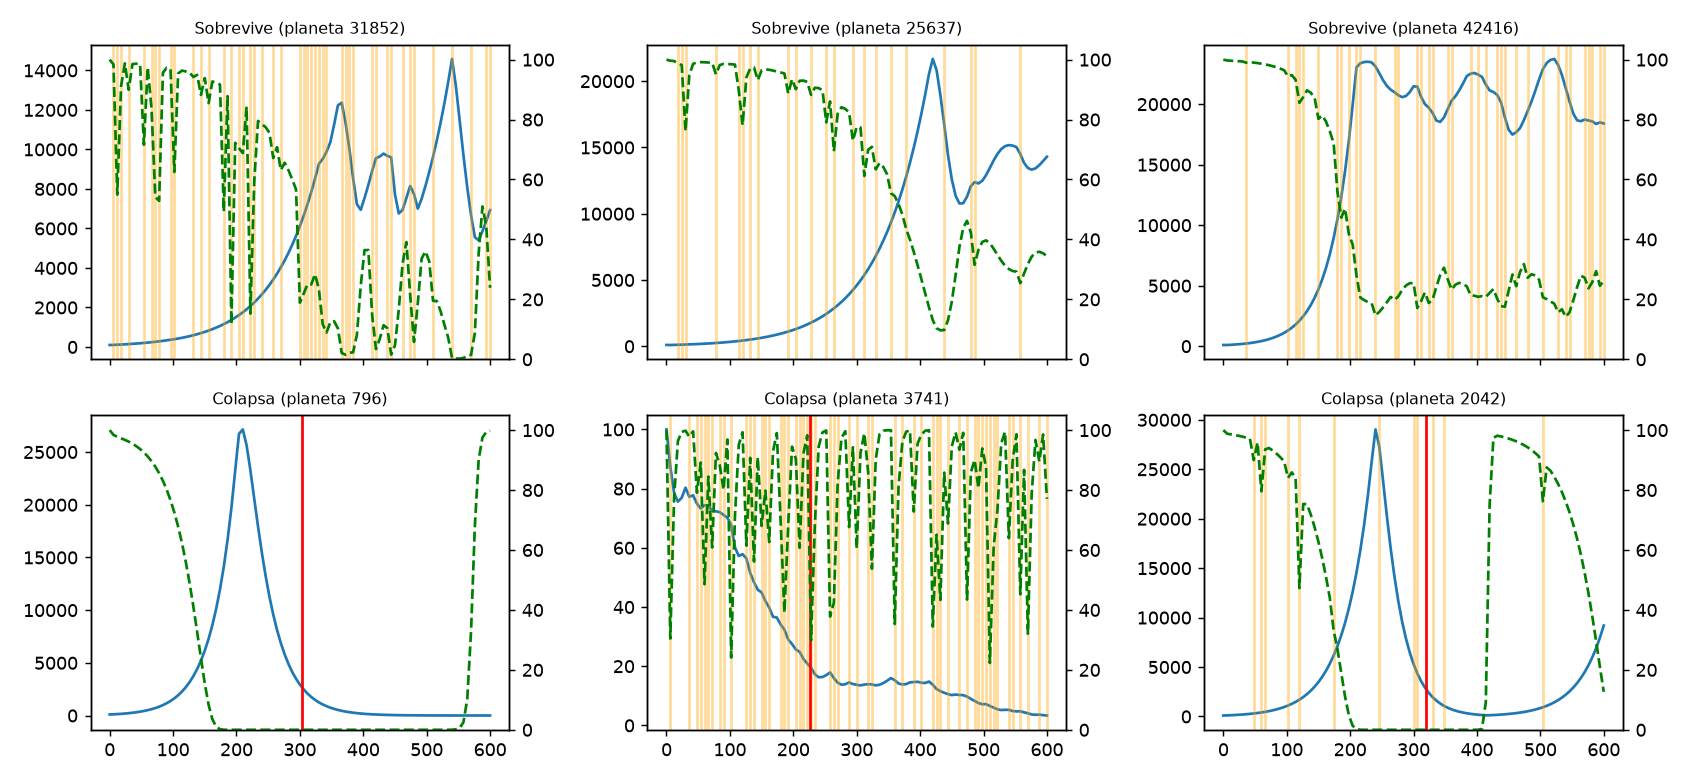

In [4]:
display(Image('report/figures/fig_eda_trayectorias.png'))

## Frontera de decisión: supervivencia por decil de cada factor

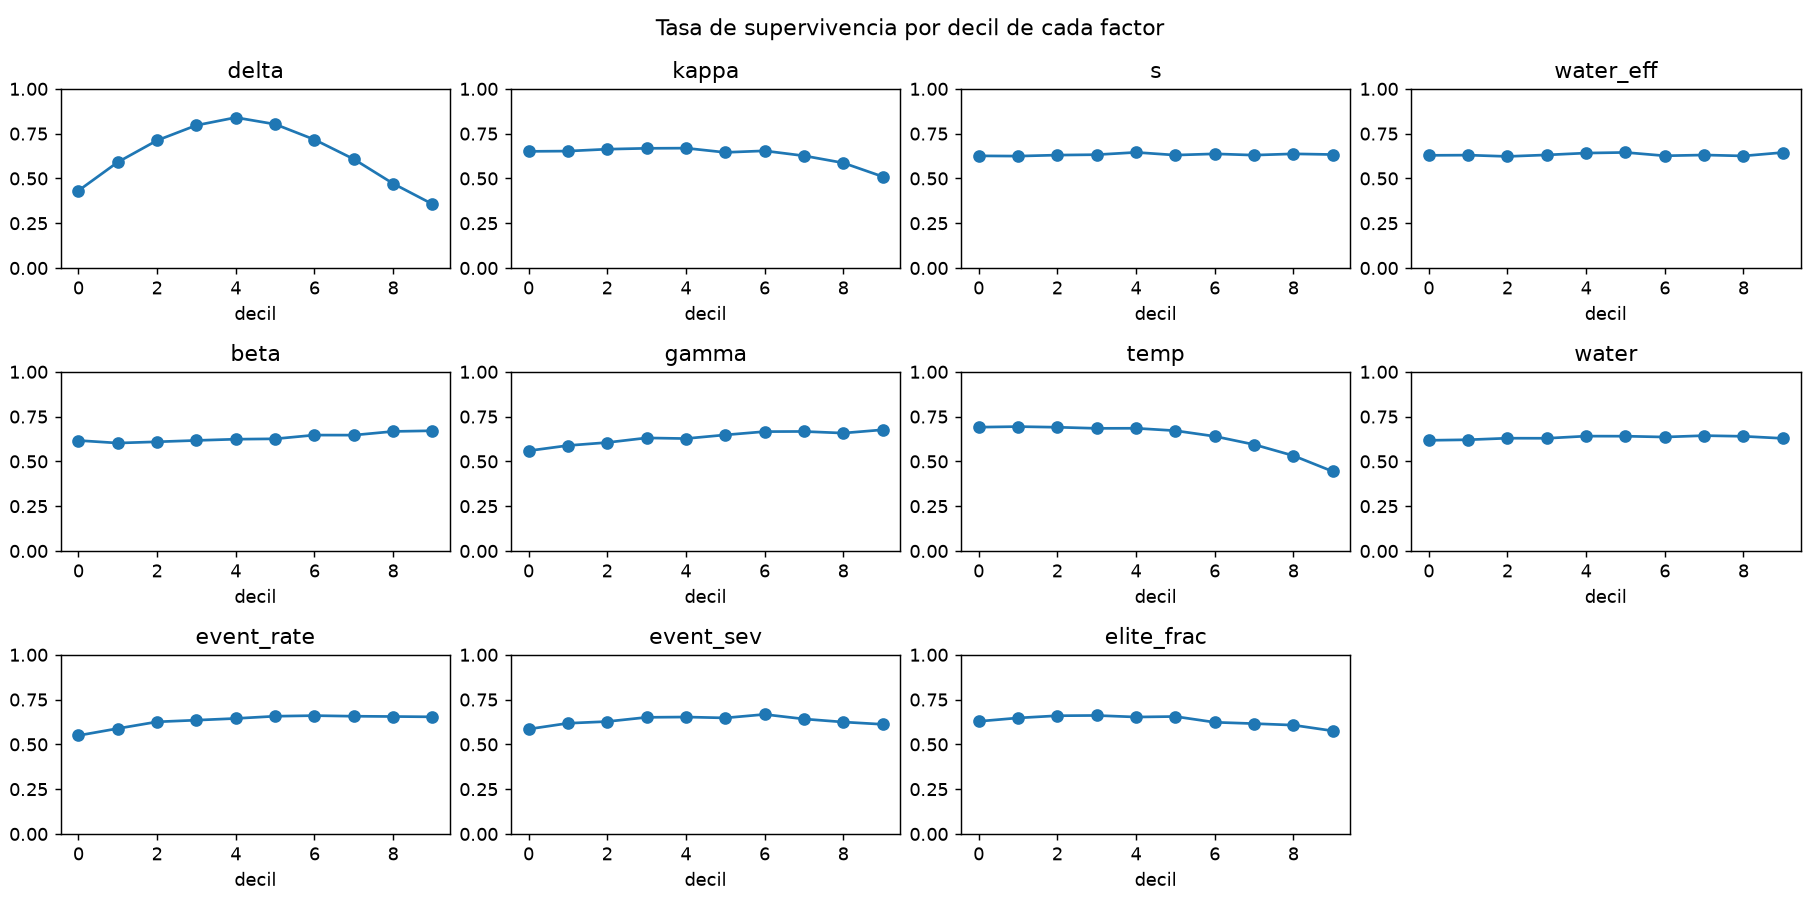

In [5]:
display(Image('report/figures/fig_eda_supervivencia_por_factor.png'))

## Subconjunto Monte Carlo (probabilidad verdadera)
500 planetas de test × 32 réplicas con distintas semillas de eventos.

In [6]:
import matplotlib.pyplot as plt
plt.hist(w.mc_p_true, bins=33); plt.xlabel('P(sobrevive) verdadera'); plt.ylabel('planetas'); plt.show()
print('fracción con P en (0.05, 0.95):', stats['mc_share_intermediate'])

fracción con P en (0.05, 0.95): 0.178
